# Zero-Shot Time-Series Forecasting on AMD CPU

**Authors:** Shailen Sobhee  
**Knowledge level:** Beginner  
**Category:** Inference

> This tutorial does not assume prior time-series or forecasting background. Run the cells top to bottom. No model training and no per-dataset tuning are required.

## Introduction

[Timestral](https://huggingface.co/collections/mistralai/timestral) by Mistral AI forecasts any time series **zero-shot**, and it runs happily on **CPU** (no GPU required). This notebook runs it on an **AMD EPYC** server, reproduces the model's headline CPU latency, and shows the NUMA / thread tuning that matters on a multi-socket AMD box.

For the GPU version of this tutorial (AMD Instinct MI300X), see `timestral_amd_tutorial.ipynb`. For the full benchmark write-up and the AMD EPYC vs MI300X comparison, see `CPU_BENCHMARKS.md`.

## Preview: what the forecast looks like

Here is the zero-shot forecast you reproduce in this notebook: a held-out 2-day window predicted from 3 weeks of 15-minute history, produced on an **AMD EPYC CPU** with the 5M model. The solid line is the median prediction; the shaded bands are the model's probability quantiles. **This is what you should see once the plotting cell runs.** The image is embedded directly here so it is visible even before you execute anything.

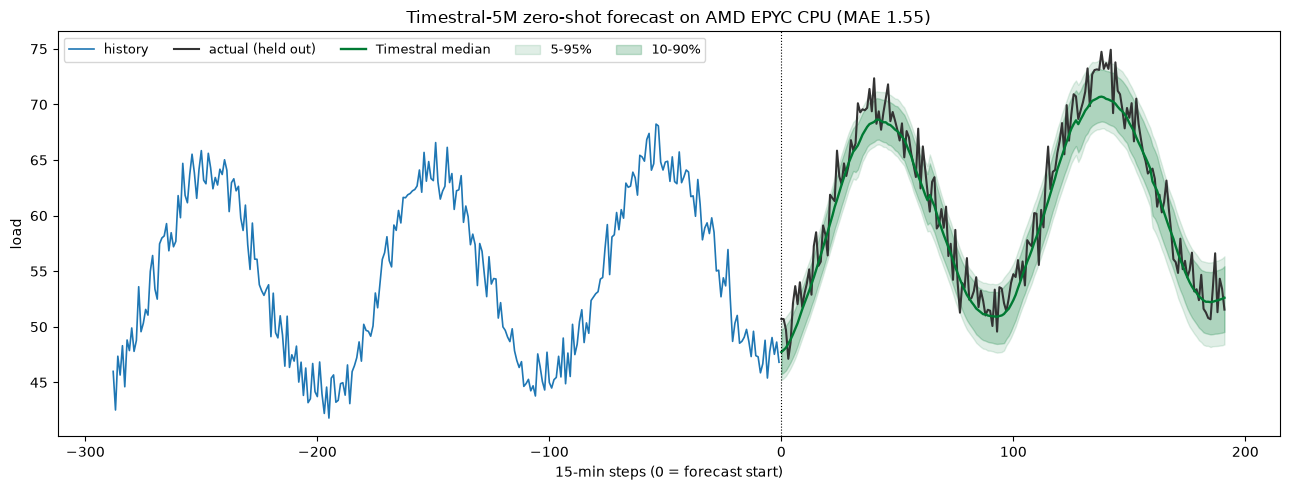

## Prerequisites

**Hardware:** 1 AMD CPU (no accelerator required). The notebook was executed end to end on the AMD EPYC machine below with the same code and the same CPU PyTorch wheels. There is no per-device branch.

| Validated hardware | Class | Accelerator required |
|---|---|---|
| AMD EPYC (2-socket, 256 physical cores, 2 NUMA nodes) | Zen4-class server CPU | None |

**Minimum configuration:** any modern AMD CPU. The 5M model answers a single forecast in **under 10 ms** on AMD EPYC; a laptop-class AMD CPU runs the same code at lower throughput.

| Item | Version |
|---|---|
| PyTorch | `2.14.1+cpu` (oneDNN / MKL-DNN enabled) |
| Python | 3.11 |
| Timestral | standalone inference package (`pip install timestral`) |
| OS | Linux (any recent distribution) |

No API token and no external dataset download. Timestral weights are fetched once from the Hugging Face Hub on first use.


## 1. Install (CPU wheels)

On CPU we install a CPU build of PyTorch (ships oneDNN, which uses the EPYC AVX-512 / BF16 paths) plus Timestral.

In [ ]:
%pip install -q torch --index-url https://download.pytorch.org/whl/cpu
%pip install -q "git+https://github.com/mistralai/timestral.git" numpy matplotlib

## 2. Confirm the AMD CPU and the math backend

In [2]:
import torch, platform, os
print("torch", torch.__version__)
print("oneDNN (mkldnn) available:", torch.backends.mkldnn.is_available())
print("default threads:", torch.get_num_threads())
# CPU model (Linux)
try:
    for line in open("/proc/cpuinfo"):
        if line.startswith("model name"):
            print("CPU:", line.split(":",1)[1].strip()); break
except Exception: pass
os.system("lscpu | grep -E 'Socket|NUMA node\\(s\\)|Core' || true")

torch 2.14.1+cpu
oneDNN (mkldnn) available: True
default threads: 16
CPU: AMD Eng Sample: 100-000001535-05
Core(s) per socket:                      128
Socket(s):                               2
NUMA node(s):                            2


0

## 3. The tuning that matters on a multi-socket AMD EPYC

Two rules, both measured in `CPU_BENCHMARKS.md`:

1. **Keep each inference on one NUMA node.** Spreading one job across both sockets is *slower*, because the per-forecast working set is small and cross-socket memory traffic dominates.
2. **Cap threads at the sweet spot** (~8 for the 5M model, ~16 for the 209M model). More threads past that regress.

Set the thread count **before** loading the model. For NUMA pinning, launch the process under `numactl` (shown at the end); inside a single notebook kernel we just cap the thread count.

In [3]:
import torch
# Sweet spot for the small model on AMD EPYC. Raise to 16 for Timestral-209M.
torch.set_num_threads(8)
print("threads set to", torch.get_num_threads())

threads set to 8


## 4. Load Timestral and reproduce the headline CPU latency

The announcement reported ~10 ms for the 5M model on an 8-thread CPU. Let's measure it.

In [4]:
import numpy as np, time
from timestral import TimestralForecaster

forecaster = TimestralForecaster.from_pretrained("mistralai/Timestral-5M", device="cpu")

rng = np.random.default_rng(7); spd = 96
H, horizon = 21*spd, 2*spd                       # 3 weeks history, 2-day forecast
tt = np.arange(H + horizon)
base = 50 + 10*np.sin(2*np.pi*tt/spd - 1.2) + 4*np.sin(2*np.pi*tt/(7*spd)) + 0.004*tt
full = base + rng.normal(0, 1.5, size=tt.shape)
context, truth = full[:H], full[H:H+horizon]
ctx = context.astype(np.float32)[None, None, :]

with torch.inference_mode():
    _ = forecaster.forecast(ctx, prediction_length=horizon)        # warmup
    times = []
    for _ in range(5):
        t0 = time.time(); out = forecaster.forecast(ctx, prediction_length=horizon); times.append(time.time()-t0)
print(f"Timestral-5M single-series latency on AMD CPU: {min(times)*1000:.1f} ms  (8 threads)")

/home/shailens/timestral-cpu/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 925.38it/s]

Timestral-5M single-series latency on AMD CPU: 12.7 ms  (8 threads)


### Score and plot the forecast

median MAE 1.55 vs naive 14.36  (skill 89.2%)


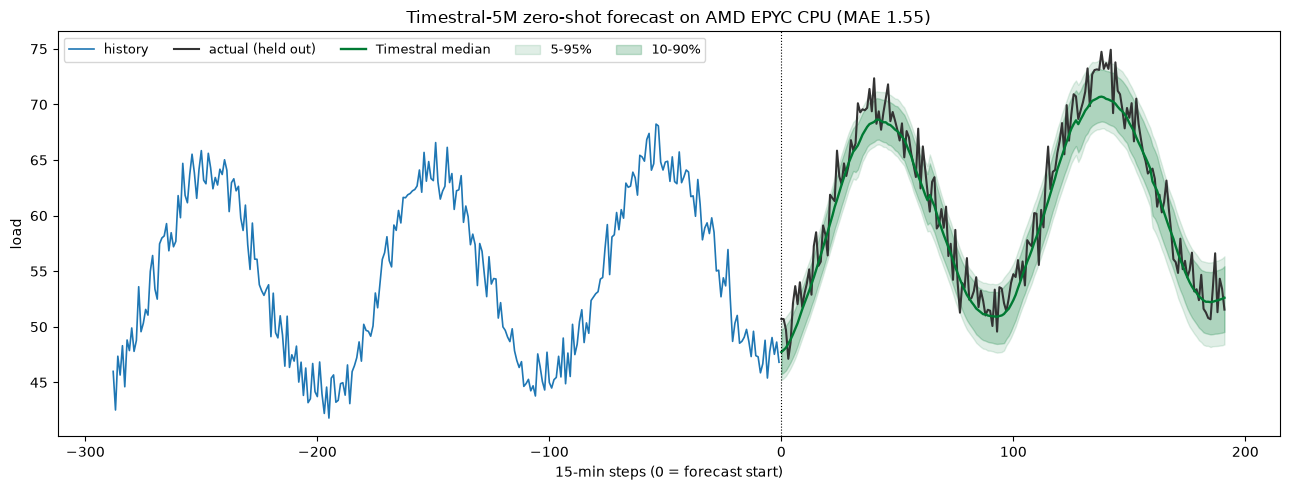

In [5]:
def to_np(x): return x.detach().float().cpu().numpy() if isinstance(x, torch.Tensor) else np.asarray(x)
med = to_np(out.median)[0,0]
mae = float(np.mean(np.abs(med-truth))); naive = float(np.mean(np.abs(context[-1]-truth)))
print(f"median MAE {mae:.2f} vs naive {naive:.2f}  (skill {1-mae/naive:.1%})")

import matplotlib.pyplot as plt
q10,q90 = to_np(out.quantile(0.1))[0,0], to_np(out.quantile(0.9))[0,0]
q05,q95 = to_np(out.quantile(0.05))[0,0], to_np(out.quantile(0.95))[0,0]
plt.figure(figsize=(13,5))
hx=np.arange(-3*spd,0); plt.plot(hx, context[hx], color="#1f77b4", lw=1.2, label="history")
fx=np.arange(0,horizon)
plt.plot(fx, truth, color="#333", lw=1.5, label="actual (held out)")
plt.plot(fx, med, color="#007a33", lw=1.7, label="Timestral median")
plt.fill_between(fx,q05,q95,color="#007a33",alpha=0.12,label="5-95%")
plt.fill_between(fx,q10,q90,color="#007a33",alpha=0.22,label="10-90%")
plt.axvline(0,color="k",ls=":",lw=0.8)
plt.title(f"Timestral-5M zero-shot forecast on AMD EPYC CPU (MAE {mae:.2f})")
plt.xlabel("15-min steps (0 = forecast start)"); plt.ylabel("load")
plt.legend(ncol=5,fontsize=9,loc="upper left"); plt.tight_layout(); plt.show()

## 5. Thread sweet-spot sweep (single kernel)

Within one process we can only change the thread count (NUMA pinning needs a fresh process via `numactl`, see the last cell). This shows the diminishing returns directly.

In [6]:
import time
batch = (base[None,None,:H] + rng.normal(0,1.5,size=(256,1,H))).astype(np.float32)
print("Timestral-5M, batch=256, throughput vs threads:")
for thr in [4, 8, 16, 32]:
    torch.set_num_threads(thr)
    with torch.inference_mode():
        _ = forecaster.forecast(batch[:16], prediction_length=horizon)   # warm
        t0=time.time(); _ = forecaster.forecast(batch, prediction_length=horizon); dt=time.time()-t0
    print(f"  {thr:3d} threads : {dt:6.3f} s = {256/dt:7.1f} series/s")

Timestral-5M, batch=256, throughput vs threads:


    4 threads :  1.879 s =   136.3 series/s


    8 threads :  0.871 s =   294.0 series/s


   16 threads :  0.674 s =   379.6 series/s


   32 threads :  0.528 s =   484.9 series/s


## 6. Using the whole machine: one worker per NUMA node

Because a single forecast peaks at a modest thread count, the right way to use all cores on a 2-socket EPYC is to run **independent workers, each pinned to one NUMA node**, and split your series across them. From a shell:

```bash
# worker on socket 0, cores 0-15, memory on node 0
OMP_NUM_THREADS=16 numactl --cpunodebind=0 --membind=0 --physcpubind=0-15 python forecast_demo.py &

# worker on socket 1, cores 128-143, memory on node 1
OMP_NUM_THREADS=16 numactl --cpunodebind=1 --membind=1 --physcpubind=128-143 python forecast_demo.py &
wait
```

The repo's `bench/cpu_sweep.sh` automates the full sweep (latency vs threads, throughput vs threads, NUMA scaling, model-size sweep) and writes JSON results. See `CPU_BENCHMARKS.md` for the measured tables and the AMD EPYC vs AMD Instinct MI300X comparison.